# Chapter 01 — Introduction to Causal Inference
Rewritten using the `probability` library (based on Matheus Facure's *Causal Inference in Python*).

In [1]:
import set_paths
import matplotlib.pyplot as plt
from make_data import load_xmas_sales, make_potential_outcomes_table
from probability.distributions import Boolean, Count, Nominal, Normal, Ratio

## 1.1 Association vs. Causation (`xmas_sales.csv`)
We wrap the columns of `xmas_sales.csv` in empirical data distributions (`Ratio`, `Boolean`, `Count`) and use the pipe conditioning operator `|` to inspect `weekly_amount_sold` given `is_on_sale`.

In [2]:
data = load_xmas_sales()
data.head(6)

,store,weeks_to_xmas,avg_week_sales,is_on_sale,weekly_amount_sold
0,1,3,12.98,1,219.60
1,1,2,12.98,1,184.70
2,1,1,12.98,1,145.75
3,1,0,12.98,0,102.45
4,2,3,19.92,0,103.22
5,2,2,19.92,0,53.73


In [3]:
weekly_sales = Ratio(data["weekly_amount_sold"])
on_sale = Boolean(data["is_on_sale"].astype(bool))
avg_week_sales = Ratio(data["avg_week_sales"])

sales_by_sale = weekly_sales | on_sale
sales_by_sale.mean()

False     63.079723
True     141.033828
dtype: float64

In [4]:
# Associational difference in means E[Y | T=1] - E[Y | T=0], 95% CI, and p-value
diff_in_means = sales_by_sale[True].mean() - sales_by_sale[False].mean()
diff_ci = sales_by_sale[True].mean_diff_ci(sales_by_sale[False], percent=0.95)
p_val = sales_by_sale[True].p_value(sales_by_sale[False])
print(f"Observed diff in means: {diff_in_means:.2f}")
print(f"95% CI: ({diff_ci[0]:.2f}, {diff_ci[1]:.2f}), p-value: {p_val:.3e}")

Observed diff in means: 77.95
95% CI: (72.33, 83.58), p-value: 0.000e+00


<Axes: title={'center': 'Distribution of p(weekly_amount_sold|is_on_sale)'}, xlabel='is_on_sale', ylabel='weekly_amount_sold'>

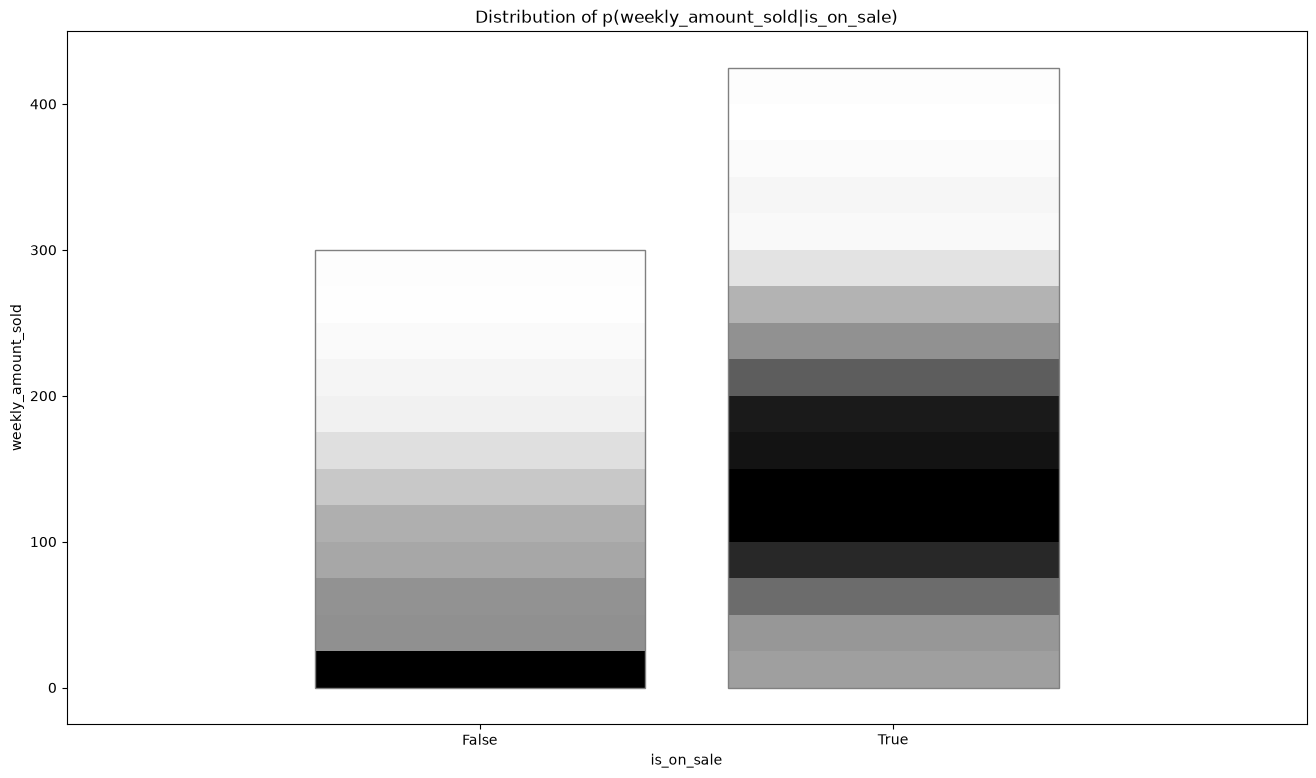

In [5]:
# Plot conditional density bars of P(weekly_amount_sold | is_on_sale)
sales_by_sale.plot_density_bars(bin_spacing=25.0);

<Axes: title={'center': ' 95% HDIs of p(weekly_amount_sold|is_on_sale)'}, xlabel='is_on_sale', ylabel='weekly_amount_sold'>

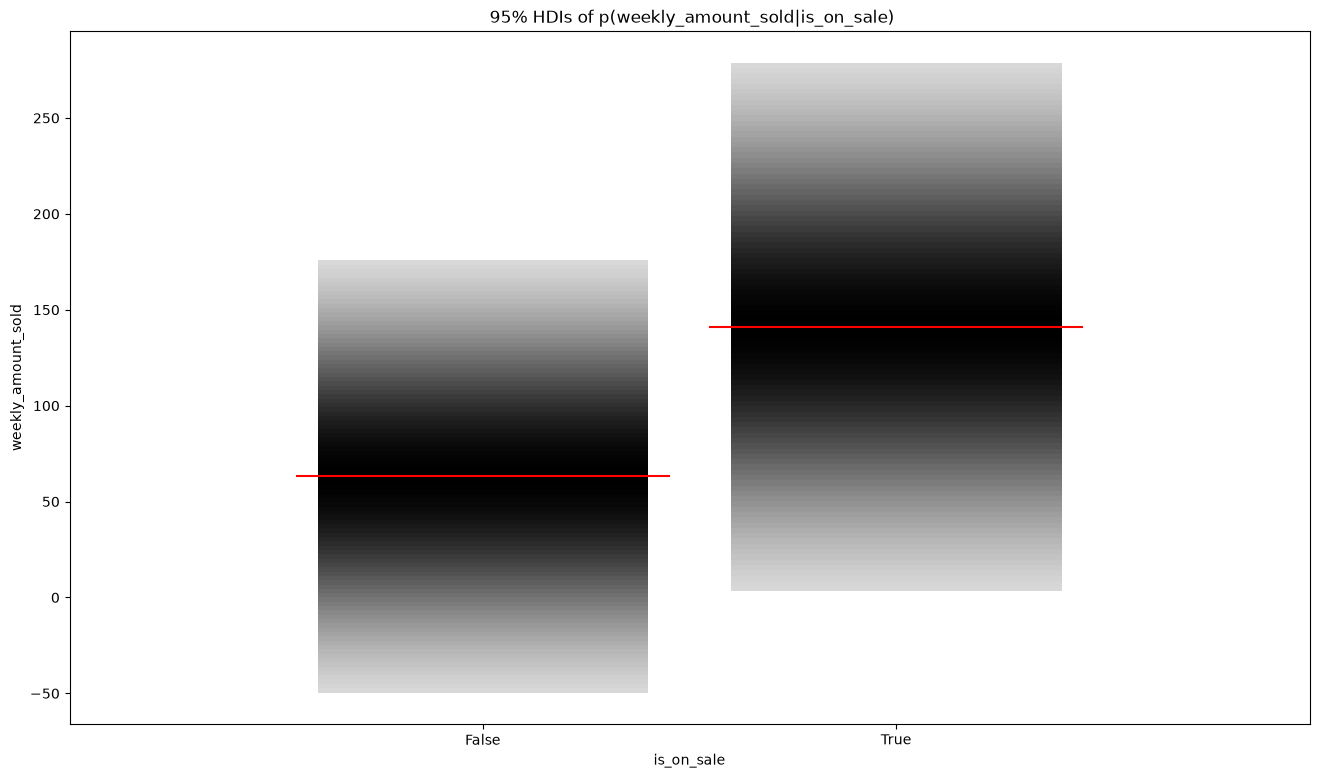

In [6]:
# Plot fitted Normal 95% HDIs of P(weekly_amount_sold | is_on_sale)
weekly_sales.plot_conditional_dist_densities(
    categorical=on_sale,
    fit_dist=Normal,
    hdi=0.95,
    color_mean="red"
);

## 1.2 Potential Outcomes & Individual Treatment Effects
Using `Ratio` and `Boolean`, we can express the potential outcomes switching equation $Y = T Y_1 + (1 - T) Y_0$ and individual treatment effect $\tau_i = Y_{1i} - Y_{0i}$.

In [7]:
po_df = make_potential_outcomes_table(observed_only=False)
Y0 = Ratio(po_df["y0"])
Y1 = Ratio(po_df["y1"])
T = Boolean(po_df["t"].astype(bool))

# Individual treatment effect Y1 - Y0 and observed outcome Y
po_df = po_df.assign(
    y=(po_df["t"] * po_df["y1"] + (1 - po_df["t"]) * po_df["y0"]).astype(int),
    te=Y1.data - Y0.data
)
po_df

,i,y0,y1,t,x,y,te
0,1,200,220,0,0,200,20
1,2,120,140,0,0,120,20
2,3,300,400,0,1,300,100
3,4,450,500,1,0,500,50
4,5,600,600,1,0,600,0
5,6,600,800,1,1,800,200


In [8]:
TE = Ratio(po_df["te"])
Y_obs = Ratio(po_df["y"])

ate = TE.mean()
att = (TE | T)[True].mean()
assoc_diff = (Y_obs | T)[True].mean() - (Y_obs | T)[False].mean()
bias = (Y0 | T)[True].mean() - (Y0 | T)[False].mean()

print(f"ATE = E[Y1 - Y0] = {ate:.2f}")
print(f"ATT = E[Y1 - Y0 | T=1] = {att:.2f}")
print(f"Bias = E[Y0 | T=1] - E[Y0 | T=0] = {bias:.2f}")
print(f"E[Y | T=1] - E[Y | T=0] = ATT + Bias = {assoc_diff:.2f}")

ATE = E[Y1 - Y0] = 65.00
ATT = E[Y1 - Y0 | T=1] = 83.33
Bias = E[Y0 | T=1] - E[Y0 | T=0] = 343.33
E[Y | T=1] - E[Y | T=0] = ATT + Bias = 426.67


## 1.3 Visual Guide to Confounding Bias
Stores with larger `avg_week_sales` are both more likely to put items on sale (`is_on_sale == True`) and sell more each week.

Standardized difference in store size (avg_week_sales): 0.638


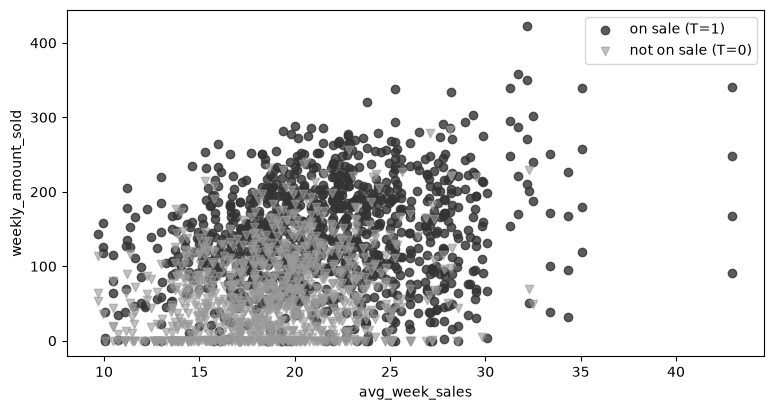

In [9]:
sales_not_on_sale = weekly_sales | on_sale.keep(False)
sales_on_sale = weekly_sales | on_sale.keep(True)
size_not_on_sale = avg_week_sales | on_sale.keep(False)
size_on_sale = avg_week_sales | on_sale.keep(True)

print("Standardized difference in store size (avg_week_sales):",
      f"{size_on_sale.normalized_diff(size_not_on_sale):.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(size_on_sale.data, sales_on_sale.data, label="on sale (T=1)", alpha=0.8, color="0.2")
ax.scatter(size_not_on_sale.data, sales_not_on_sale.data, label="not on sale (T=0)", alpha=0.6, color="0.6", marker="v")
ax.set_xlabel("avg_week_sales")
ax.set_ylabel("weekly_amount_sold")
ax.legend();